# The communication game

Companion notebook to Lecture 12, *Team games*, slides 2–8. We check every number on those slides for the communication game.

**Requirements:** `numpy`, `scipy`, `sympy`, `matplotlib`.

In [1]:
import itertools
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.optimize import linprog, minimize


def frac(t, max_denominator=1000):
    # Display helper: float close to a simple fraction.
    return str(Fraction(float(t)).limit_denominator(max_denominator))


def maxmin_lp(M):
    # max_{p in simplex} min_j (p^T M)_j for a payoff matrix M (rows: maximizer).
    # Returns (value, p).
    m, n = M.shape
    res = linprog(np.r_[np.zeros(m), -1], A_ub=np.c_[-M.T, np.ones(n)], b_ub=np.zeros(n),
                  A_eq=[np.r_[np.ones(m), 0]], b_eq=[1],
                  bounds=[(0, None)] * m + [(None, None)], method="highs")
    return -res.fun, res.x[:m]

## The game tree

Each terminal history $z \in Z$ is `(bit, msg, guess2, guess3)`. If P2 guesses wrong, play stops with utility 0 and P3 never moves (`guess3 = None`).

In [2]:
Z = []
for bit, msg in itertools.product((0, 1), repeat=2):
    Z.append((bit, msg, 1 - bit, None))          # P2 wrong: leaf 0
    for guess3 in (0, 1):
        Z.append((bit, msg, bit, guess3))        # P2 right: P3 guesses

u = np.array([1.0 if g3 is not None and g3 != bit else 0.0 for bit, _, _, g3 in Z])
p_c = np.full(len(Z), 1 / 2)                     # chance draws the bit uniformly

print(f"|Z| = {len(Z)}")
for z, uz in zip(Z, u):
    print(z, "u =", int(uz))

|Z| = 12
(0, 0, 1, None) u = 0
(0, 0, 0, 0) u = 0
(0, 0, 0, 1) u = 1
(0, 1, 1, None) u = 0
(0, 1, 0, 0) u = 0
(0, 1, 0, 1) u = 1
(1, 0, 0, None) u = 0
(1, 0, 1, 0) u = 1
(1, 0, 1, 1) u = 0
(1, 1, 0, None) u = 0
(1, 1, 1, 0) u = 1
(1, 1, 1, 1) u = 0


Behavioral labels from the slides (with $\bar x := 1 - x$):

* $a$ = P(msg 0 | bit 0), $b$ = P(msg 0 | bit 1)
* $c$ = P(P2 guesses 0 | msg 0), $d$ = P(P2 guesses 0 | msg 1)
* $e$ = P(P3 guesses 0 | msg 0), $f$ = P(P3 guesses 0 | msg 1)

In [3]:
a, b, c, d, e, f = sp.symbols("a b c d e f")
bar = lambda t: 1 - t
P_msg = {(0, 0): a, (0, 1): bar(a), (1, 0): b, (1, 1): bar(b)}   # (bit, msg)
P_g2 = {(0, 0): c, (0, 1): bar(c), (1, 0): d, (1, 1): bar(d)}    # (msg, guess2)
P_g3 = {(0, 0): e, (0, 1): bar(e), (1, 0): f, (1, 1): bar(f)}    # (msg, guess3)

x_sym = [P_msg[bit, msg] * P_g2[msg, g2] for bit, msg, g2, g3 in Z]               # team realization
y_sym = [1 if g3 is None else P_g3[msg, g3] for bit, msg, g2, g3 in Z]             # adversary realization
u_sym = sp.expand(sum(pc * uz * xz * yz for pc, uz, xz, yz in zip(p_c, u, x_sym, y_sym)))

slide2 = sp.Rational(1, 2) * (a*c*bar(e) + bar(a)*d*bar(f) + b*bar(c)*e + bar(b)*bar(d)*f)
print("u(a,...,f) equals the slide-2 formula:", sp.simplify(u_sym - sp.nsimplify(slide2)) == 0)
print("team realization x[z] (slide 8 red labels):")
for z, xz in zip(Z, x_sym):
    print(" ", z, xz)

u(a,...,f) equals the slide-2 formula: True
team realization x[z] (slide 8 red labels):
  (0, 0, 1, None) a*(1 - c)
  (0, 0, 0, 0) a*c
  (0, 0, 0, 1) a*c
  (0, 1, 1, None) (1 - a)*(1 - d)
  (0, 1, 0, 0) d*(1 - a)
  (0, 1, 0, 1) d*(1 - a)
  (1, 0, 0, None) b*c
  (1, 0, 1, 0) b*(1 - c)
  (1, 0, 1, 1) b*(1 - c)
  (1, 1, 0, None) d*(1 - b)
  (1, 1, 1, 0) (1 - b)*(1 - d)
  (1, 1, 1, 1) (1 - b)*(1 - d)


In [4]:
U_fn = sp.lambdify((a, b, c, d, e, f), sp.nsimplify(slide2), "numpy")

## Pure plans

Every player acts once on each path, so reduced plans equal full plans.

In [5]:
Pi1 = list(itertools.product((0, 1), repeat=2))   # (msg if bit 0, msg if bit 1)
Pi2 = list(itertools.product((0, 1), repeat=2))   # (guess if msg 0, guess if msg 1)
Pi3 = list(itertools.product((0, 1), repeat=2))   # (guess if msg 0, guess if msg 1)
print(f"|Pi_1| = {len(Pi1)}, |Pi_2| = {len(Pi2)}, |Pi_3| = {len(Pi3)}, |Pi_1 x Pi_2| = {len(Pi1) * len(Pi2)}")


def to_beh(plan, player):
    # Pure plan -> behavioral labels (a, b), (c, d) or (e, f).
    if player == 1:
        return tuple(1 - m for m in plan)          # a = 1 iff msg 0 on bit 0, etc.
    return tuple(1 - g for g in plan)              # c = 1 iff guess 0 on msg 0, etc.


team_plans = list(itertools.product(Pi1, Pi2))
M = np.array([[U_fn(*to_beh(p1, 1), *to_beh(p2, 2), *to_beh(p3, 3)) for p3 in Pi3]
              for p1, p2 in team_plans])          # team pure plans x adversary pure plans

|Pi_1| = 4, |Pi_2| = 4, |Pi_3| = 4, |Pi_1 x Pi_2| = 16


## TME: $\max_{\mathbf{x}_1, \mathbf{x}_2} \min_{\mathbf{y}} u$ (slide 2)

$u$ is affine in $(e, f)$, so the inner min is attained at one of P3's four pure plans.

In [6]:
def tme_objective(a_, b_, c_, d_):
    return np.min([U_fn(a_, b_, c_, d_, *to_beh(p3, 3)) for p3 in Pi3], axis=0)


grid = np.linspace(0, 1, 21)
A, B, C, D = np.meshgrid(grid, grid, grid, grid, indexing="ij")
vals = tme_objective(A, B, C, D)
print("grid max:", frac(vals.max()))

rng = np.random.default_rng(0)
best = max(-minimize(lambda p: -tme_objective(*p), rng.random(4), bounds=[(0, 1)] * 4,
                     method="Nelder-Mead").fun for _ in range(100))
print("multistart optimizer max:", round(best, 6))
print("at a = b = c = d = 1/2:", frac(tme_objective(.5, .5, .5, .5)))

grid max: 1/4


multistart optimizer max: 0.25
at a = b = c = d = 1/2: 1/4


The maximizer is not unique. On the grid, every maximizer has $a = b$ (the message carries no information about the bit).

In [7]:
arg = np.argwhere(np.isclose(vals, 0.25))
pts = grid[arg]
print("grid maximizers:", len(pts))
print("all have a == b:", np.allclose(pts[:, 0], pts[:, 1]))
for row in pts[[0, 1, 25, -2, -1]]:
    print("  (a, b, c, d) =", tuple(frac(t) for t in row))

grid maximizers: 61
all have a == b: True
  (a, b, c, d) = ('0', '0', '0', '1/2')
  (a, b, c, d) = ('0', '0', '1/20', '1/2')
  (a, b, c, d) = ('1/4', '1/4', '1/2', '1/2')
  (a, b, c, d) = ('1', '1', '1/2', '19/20')
  (a, b, c, d) = ('1', '1', '1/2', '1')


## $\min_{\mathbf{y}} \max_{\mathbf{x}_1, \mathbf{x}_2} u$ (slide 3)

For fixed $\mathbf{y}$, $u$ is multilinear in the team's behavioral strategies, so the inner max is attained at a pure team plan.

In [8]:
eg = np.linspace(0, 1, 101)
E, F = np.meshgrid(eg, eg, indexing="ij")
team_br = np.max([U_fn(*to_beh(p1, 1), *to_beh(p2, 2), E, F) for p1, p2 in team_plans], axis=0)
i, j = np.unravel_index(team_br.argmin(), team_br.shape)
print("min over (e, f) of team best response:", frac(team_br.min()), f" at (e, f) = ({eg[i]:g}, {eg[j]:g})")
print("equals (1 + |e - f|)/2 everywhere:", np.allclose(team_br, (1 + abs(E - F)) / 2))
print(f"max-min = {frac(vals.max())} < {frac(team_br.min())} = min-max")

min over (e, f) of team best response: 1/2  at (e, f) = (0, 0)
equals (1 + |e - f|)/2 everywhere: True
max-min = 1/4 < 1/2 = min-max


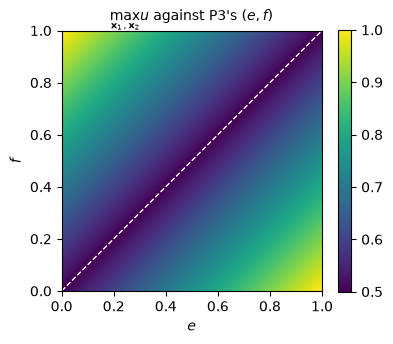

In [9]:
fig, ax = plt.subplots(figsize=(4.2, 3.4))
im = ax.imshow(team_br.T, origin="lower", extent=[0, 1, 0, 1], cmap="viridis")
ax.plot([0, 1], [0, 1], color="white", ls="--", lw=1)
ax.set_xlabel("$e$")
ax.set_ylabel("$f$")
ax.set_title(r"$\max_{\mathbf{x}_1,\mathbf{x}_2} u$ against P3's $(e, f)$", fontsize=10)
fig.colorbar(im, ax=ax)
plt.show()

## Nash equilibrium (slide 4)

$(a, b; c, d; e, f) = (1, 0; 1, 0; 1, 0)$. Check every unilateral deviation on a grid.

In [10]:
profile = dict(a=1, b=0, c=1, d=0, e=1, f=0)
print("team value:", U_fn(**profile))
g11 = np.linspace(0, 1, 11)
for player, keys in [("P1", "ab"), ("P2", "cd"), ("P3", "ef")]:
    dev = [U_fn(**{**profile, **dict(zip(keys, v))}) for v in itertools.product(g11, repeat=2)]
    print(f"{player} deviations: team value in [{min(dev)}, {max(dev)}]")
print("joint team deviation (0,1;0,1) against (e,f) = (1,0):", U_fn(0, 1, 0, 1, 1, 0))

team value: 0.0
P1 deviations: team value in [0.0, 0.0]
P2 deviations: team value in [0.0, 0.0]
P3 deviations: team value in [0.0, 1.0]
joint team deviation (0,1;0,1) against (e,f) = (1,0): 1.0


P1 and P2 cannot gain alone, P3 already holds the team at 0. A *joint* team deviation would reach 1.

## TMECor (slide 6)

LP over $\boldsymbol\mu \in \Delta(\Pi_1 \times \Pi_2)$ against $\mathbf{y} \in \Delta(\Pi_3)$.

In [11]:
v_cor, mu = maxmin_lp(M)
v_dual, y_opt = maxmin_lp(-M.T)
print("TMECor value (max-min):", frac(v_cor))
print("min-max over y:", frac(-v_dual))
for k in np.flatnonzero(mu > 1e-9):
    print("  mu =", frac(mu[k]), "on team plan", team_plans[k])

TMECor value (max-min): 1/2
min-max over y: 1/2
  mu = 1/2 on team plan ((0, 1), (0, 1))
  mu = 1/2 on team plan ((1, 0), (1, 0))


The "random one-time pad": uniform over $(1,0;1,0)$ and $(0,1;0,1)$.

In [12]:
pad = [(1, 0, 1, 0), (0, 1, 0, 1)]
for p3 in Pi3:
    value = np.mean([U_fn(*t, *to_beh(p3, 3)) for t in pad])
    print(f"vs P3 plan (e, f) = {to_beh(p3, 3)}: {frac(value)}")
print("best team plan vs e = f = 1/2:", frac(max(U_fn(*to_beh(p1, 1), *to_beh(p2, 2), .5, .5)
                                               for p1, p2 in team_plans)))

vs P3 plan (e, f) = (1, 1): 1/2
vs P3 plan (e, f) = (1, 0): 1/2
vs P3 plan (e, f) = (0, 1): 1/2
vs P3 plan (e, f) = (0, 0): 1/2
best team plan vs e = f = 1/2: 1/2


## Realization form (slide 8)

$V \subseteq \{0,1\}^Z$ for the team, $W$ for the adversary, and $U[z,z] = p_c(z) \cdot u(z)$.

In [13]:
def team_vec(p1, p2):
    return np.array([float(p1[bit] == msg and p2[msg] == g2) for bit, msg, g2, g3 in Z])


def adv_vec(p3):
    return np.array([1.0 if g3 is None else float(p3[msg] == g3) for bit, msg, g2, g3 in Z])


V = np.unique([team_vec(p1, p2) for p1, p2 in team_plans], axis=0)
W = np.unique([adv_vec(p3) for p3 in Pi3], axis=0)
U = np.diag(p_c * u)
print(f"|Z| = {len(Z)}, |V| = {len(V)}, |W| = {len(W)}")

v_real, lam = maxmin_lp(V @ U @ W.T)
print("max_{x in conv V} min_{y in conv W} x^T U y =", frac(v_real))

|Z| = 12, |V| = 12, |W| = 4
max_{x in conv V} min_{y in conv W} x^T U y = 1/2


$|V| = 12 < 16$: when P1 always sends the same message, P2's plan at the other message is never reached.

## Is conv $V$ cut out by flow constraints?

The natural linear relaxation $R$: $x \ge 0$, total mass 1 per bit, and both P3 children of a node carry the same mass. It is the realization polytope of the team when P2 also sees the bit (perfect recall). We enumerate the vertices of $R$, and of $R$ plus the four inequalities $x(0, m, g) + x(1, m, 1-g) \le 1$, where $x(\text{bit}, m, g)$ is the mass on (bit, msg $m$, P2 guess $g$).

In [14]:
n = len(Z)
idx = {z[:3]: k for k, z in enumerate(Z)}             # first leaf of each (bit, msg, guess2)

A_eq, b_eq = [], []
for bit in (0, 1):                                    # mass 1 per bit
    A_eq.append([float(z[0] == bit and (z[3] is None or z[3] == 0)) for z in Z]); b_eq.append(1)
for k, z in enumerate(Z):                             # both P3 children carry the same mass
    if z[3] == 1:
        row = np.zeros(n); row[k] = 1; row[k - 1] = -1
        A_eq.append(row); b_eq.append(0)
A_eq, b_eq = np.array(A_eq), np.array(b_eq, dtype=float)

A_nonneg, b_nonneg = -np.eye(n), np.zeros(n)
A_cons, b_cons = [], []                                # P2's guess cannot depend on the bit
for msg, g in itertools.product((0, 1), repeat=2):
    row = np.zeros(n); row[idx[0, msg, g]] = 1; row[idx[1, msg, 1 - g]] = 1
    A_cons.append(row); b_cons.append(1)
A_cons, b_cons = np.array(A_cons), np.array(b_cons, dtype=float)


def vertices(A_ub, b_ub, tol=1e-9):
    # Brute-force vertex enumeration of {A_eq x = b_eq, A_ub x <= b_ub}.
    k = n - np.linalg.matrix_rank(A_eq)
    found = set()
    for S in itertools.combinations(range(len(A_ub)), k):
        L = np.r_[A_eq, A_ub[list(S)]]
        if np.linalg.matrix_rank(L) < n:
            continue
        x = np.linalg.lstsq(L, np.r_[b_eq, b_ub[list(S)]], rcond=None)[0]
        if np.all(A_ub @ x <= b_ub + tol):
            found.add(tuple(np.round(x, 9) + 0.0))
    return np.array(sorted(found))


as_set = lambda P: {tuple(row) for row in np.round(P, 9) + 0.0}
R_vertices = vertices(A_nonneg, b_nonneg)
H_vertices = vertices(np.r_[A_nonneg, A_cons], np.r_[b_nonneg, b_cons])
print("dim conv V =", np.linalg.matrix_rank(V - V.mean(0)))
print("vertices of R:", len(R_vertices), " in V:", len(as_set(R_vertices) & as_set(V)))
print("R + 4 inequalities has vertex set exactly V:", as_set(H_vertices) == as_set(V))

dim conv V = 6
vertices of R: 16  in V: 12
R + 4 inequalities has vertex set exactly V: True


The four extra vertices of $R$ are "P1 always sends the same message, and P2 still gets the bit right (or wrong) on both bits". They need P2 to know the bit.

In [15]:
for v in R_vertices:
    if tuple(v) not in as_set(V):
        print(", ".join(f"bit {bit}: msg {msg}, P2 guesses {g2}"
                        for k, (bit, msg, g2, g3) in enumerate(Z) if v[k] and g3 != 1))

v_relax, _ = maxmin_lp(R_vertices @ U @ W.T)
print("game value over R:", frac(v_relax))

bit 0: msg 1, P2 guesses 0, bit 1: msg 1, P2 guesses 1
bit 0: msg 1, P2 guesses 1, bit 1: msg 1, P2 guesses 0
bit 0: msg 0, P2 guesses 0, bit 1: msg 0, P2 guesses 1
bit 0: msg 0, P2 guesses 1, bit 1: msg 0, P2 guesses 0
game value over R: 1/2


In this game the relaxation does not change the value: P3 sees only the message, so even a P2 who knows the bit wins at most $1/2$.

## Behavioral realizations are nonconvex (slide 7)

The two one-time-pad plans are behavioral strategies of the merged team player. Their midpoint is in conv $V$, but no behavioral $(a, b, c, d)$ reaches it.

In [16]:
x_beh = sp.lambdify((a, b, c, d), x_sym, "numpy")
mid = (np.array(x_beh(1, 0, 1, 0), float) + np.array(x_beh(0, 1, 0, 1), float)) / 2
in_convV = linprog(np.zeros(len(V)), A_eq=np.r_[V.T, np.ones((1, len(V)))], b_eq=np.r_[mid, 1],
                   bounds=[(0, None)] * len(V), method="highs").status == 0
dist = min(minimize(lambda p: np.sum((np.array(x_beh(*p), float) - mid) ** 2), rng.random(4),
                    bounds=[(0, 1)] * 4).fun for _ in range(100))
print("midpoint in conv V:", in_convV)
print("min squared distance from a behavioral realization to the midpoint:", round(dist, 6))

midpoint in conv V: True
min squared distance from a behavioral realization to the midpoint: 0.75


Reaching the midpoint needs $ac = 1/2$ and $a\bar c = 0$, so $c = 1$, but also $b\bar c = 1/2$, so $c < 1$.